# **Hit Song Popularity Prediction (Regression)**
### **Course: AI101 - Data Science and AI Essentials with Python**
**School of AI & Data Engineering, IIT Ropar**

---

### **Project Overview & Objectives**
- **Statement:** Hit Song Popularity Prediction (Regression)
- **Goal:** Predict a music track's continuous popularity score (0-100) using acoustic and audio features (danceability, energy, acousticness, tempo, instrumentalness, loudness, etc.).
- **Models Benchmarked:** Multiple Linear Regression (OLS), Ridge Regression ($L_2$), Lasso Regression ($L_1$), Decision Tree Regressor, and Random Forest Regressor.
- **Evaluation Metrics:** $R^2$ Score, Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and Diagnostic Residual Plots.
- **Dataset:** Spotify Tracks Dataset (114,000 records).

---


### **1. Library Imports & Environment Setup**
We import the foundational data science libraries: `numpy`, `pandas`, `matplotlib`, `seaborn`, and `scikit-learn`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

# Set visual style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.sans-serif': 'Arial', 'font.size': 11})

print("All libraries successfully imported!")

All libraries successfully imported!


### **2. Dataset Ingestion & Inspection**
Load the dataset from the relative repository path `../data/dataset.csv` or `data/dataset.csv`.


In [2]:
# Support running from either repo root or notebooks/ subfolder
data_path = 'data/dataset.csv' if os.path.exists('data/dataset.csv') else '../data/dataset.csv'
df_raw = pd.read_csv(data_path)

print(f"Raw dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
df_raw.head()

Raw dataset shape: 114000 rows, 21 columns


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
# Inspect column data types and missing values
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

### **3. Data Preprocessing & Deduplication**
- Remove unnecessary indexing columns (e.g., `Unnamed: 0`).
- Check and drop missing values (`dropna()`).
- Remove duplicate tracks by `track_id` to ensure no track leakage across training and test splits.
- Convert boolean fields like `explicit` to binary indicators (0 or 1).


In [4]:
df = df_raw.copy()
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

df = df.dropna().reset_index(drop=True)

initial_count = len(df)
df = df.drop_duplicates(subset=['track_id']).reset_index(drop=True)
print(f"Dropped {initial_count - len(df)} duplicate track entries.")
print(f"Cleaned unique tracks count: {len(df)}")

if 'explicit' in df.columns:
    df['explicit'] = df['explicit'].astype(int)

df['popularity'].describe()

Dropped 24259 duplicate track entries.


Cleaned unique tracks count: 89740


count    89740.000000
mean        33.198808
std         20.580640
min          0.000000
25%         19.000000
50%         33.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64

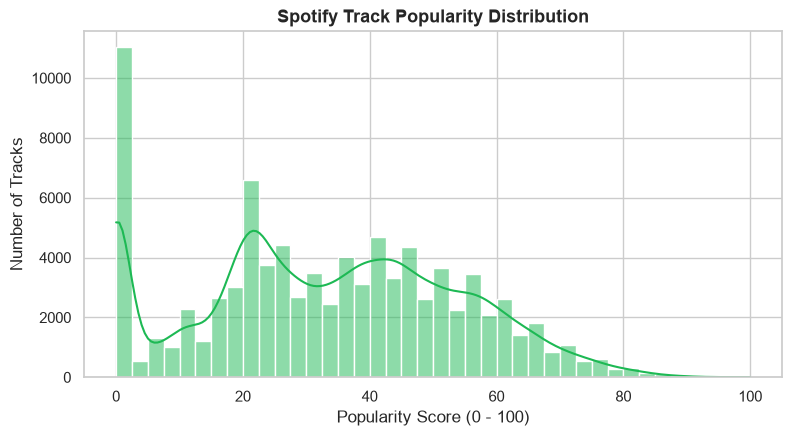

In [5]:
# Visualizing Target Variable Distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(df['popularity'], kde=True, bins=40, color='#1DB954')
plt.title("Spotify Track Popularity Distribution", fontsize=13, weight='bold')
plt.xlabel("Popularity Score (0 - 100)")
plt.ylabel("Number of Tracks")
plt.show()

### **4. Feature Selection & Correlation Analysis**
We inspect the core audio features defined by the Spotify Web API:
- `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`
- `instrumentalness`, `liveness`, `valence`, `tempo`, `duration_ms`
- `key`, `mode`, `time_signature`


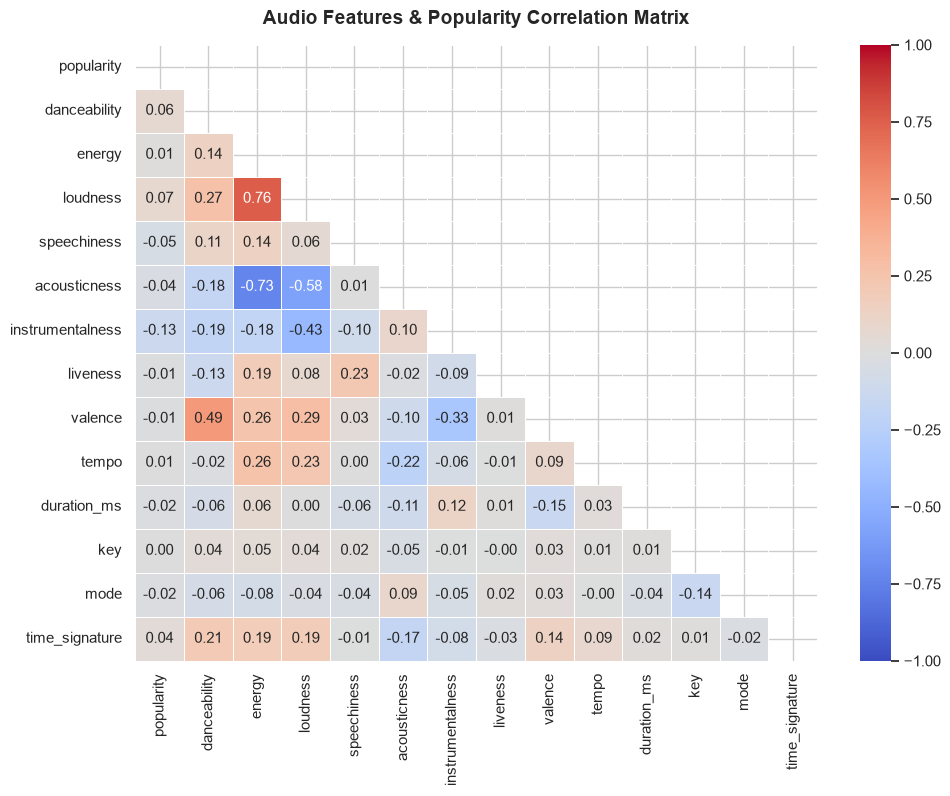

Top Correlations with Popularity:
popularity          1.000000
loudness            0.071674
danceability        0.064275
time_signature      0.036898
energy              0.013725
tempo               0.007280
key                 0.003441
valence            -0.011508
liveness           -0.013857
mode               -0.016238
duration_ms        -0.023157
acousticness       -0.038828
speechiness        -0.047086
instrumentalness   -0.127477
Name: popularity, dtype: float64


In [6]:
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence',
    'tempo', 'duration_ms', 'key', 'mode', 'time_signature'
]

# Pearson correlation matrix
corr = df[['popularity'] + audio_features].corr()

plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Audio Features & Popularity Correlation Matrix", fontsize=14, weight='bold', pad=15)
plt.show()

print("Top Correlations with Popularity:")
print(corr['popularity'].sort_values(ascending=False))

### **5. Data Splitting & Feature Standardization**
We split the data into an **80% training set** and a **20% testing set** with a fixed random seed (`random_state=42`).
Continuous audio features are standardized using `StandardScaler` to have zero mean and unit variance ($\mu=0, \sigma=1$).


In [7]:
X = df[audio_features]
y = df['popularity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=audio_features, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=audio_features, index=X_test.index)

print(f"Training set: {X_train_scaled.shape[0]} samples")
print(f"Testing set:  {X_test_scaled.shape[0]} samples")

Training set: 71792 samples
Testing set:  17948 samples


### **6. Model Training & Evaluation Functions**
We define modular helper functions to train regression models and record $R^2$, RMSE, and MAE.


In [8]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te, name="Model"):
    model.fit(X_tr, y_tr)
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)
    
    metrics = {
        'Model': name,
        'Train R2': r2_score(y_tr, y_tr_pred),
        'Test R2': r2_score(y_te, y_te_pred),
        'Train RMSE': root_mean_squared_error(y_tr, y_tr_pred),
        'Test RMSE': root_mean_squared_error(y_te, y_te_pred),
        'Train MAE': mean_absolute_error(y_tr, y_tr_pred),
        'Test MAE': mean_absolute_error(y_te, y_te_pred)
    }
    return metrics, y_te_pred

### **7. Training the Models (Linear, Ridge, Lasso, Decision Tree, Random Forest)**
We benchmark all 5 models on the exact same train/test split.


In [9]:
models_to_test = {
    'Multiple Linear Regression': (LinearRegression(), X_train_scaled, X_test_scaled),
    'Ridge Regression (L2)': (Ridge(alpha=10.0, random_state=42), X_train_scaled, X_test_scaled),
    'Lasso Regression (L1)': (Lasso(alpha=0.05, random_state=42), X_train_scaled, X_test_scaled),
    'Decision Tree Regressor': (DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42), X_train, X_test),
    'Random Forest Regressor': (RandomForestRegressor(n_estimators=35, max_depth=12, min_samples_leaf=10, random_state=42), X_train, X_test)
}

results = []
predictions = {}

for name, (model, X_tr, X_te) in models_to_test.items():
    print(f"Training {name}...")
    metrics, y_pred = evaluate_model(model, X_tr, y_train, X_te, y_test, name=name)
    results.append(metrics)
    predictions[name] = y_pred

results_df = pd.DataFrame(results)
results_df

Training Multiple Linear Regression...
Training Ridge Regression (L2)...
Training Lasso Regression (L1)...


Training Decision Tree Regressor...


Training Random Forest Regressor...


,Model,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Multiple Linear Regression,0.031969,0.029321,20.280533,20.148756,16.704373,16.597664
1,Ridge Regression (L2),0.031969,0.029322,20.280533,20.148748,16.704446,16.597730
2,Lasso Regression (L1),0.031828,0.029375,20.282010,20.148195,16.721747,16.612527
3,Decision Tree Regressor,0.105581,0.078532,19.494188,19.631368,15.712880,15.826197
4,Random Forest Regressor,0.242916,0.149332,17.935221,18.862119,14.276768,15.127042


### **8. Model Interpretability & Feature Importance**
Comparing standardized linear regression coefficients vs. non-linear decision tree Gini feature importances.


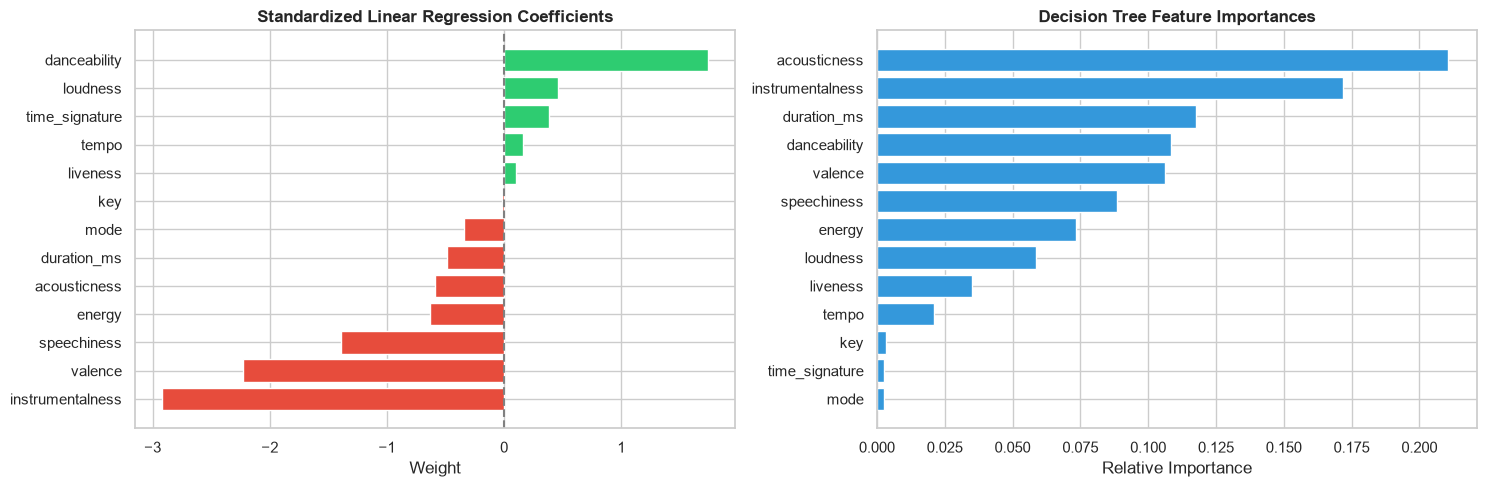

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Linear Regression Coefficients
lr_model = models_to_test['Multiple Linear Regression'][0]
coef_df = pd.DataFrame({'Feature': audio_features, 'Coefficient': lr_model.coef_}).sort_values('Coefficient')
ax1.barh(coef_df['Feature'], coef_df['Coefficient'], color=['#e74c3c' if c < 0 else '#2ecc71' for c in coef_df['Coefficient']])
ax1.axvline(0, color='gray', linestyle='--')
ax1.set_title("Standardized Linear Regression Coefficients", weight='bold')
ax1.set_xlabel("Weight")

# Decision Tree Importance
dt_model = models_to_test['Decision Tree Regressor'][0]
dt_df = pd.DataFrame({'Feature': audio_features, 'Importance': dt_model.feature_importances_}).sort_values('Importance')
ax2.barh(dt_df['Feature'], dt_df['Importance'], color='#3498db')
ax2.set_title("Decision Tree Feature Importances", weight='bold')
ax2.set_xlabel("Relative Importance")

plt.tight_layout()
plt.show()

### **9. Diagnostic Residual Plots & Error Analysis**
Examining residual plots ($y - \hat{y}$) to verify regression assumptions:
- Homoscedasticity (constant variance)
- Normality of residuals (symmetric bell curve centered at 0)


<>:16: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:16: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
C:\Users\aadit\AppData\Local\Temp\ipykernel_21480\1249434980.py:16: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  axes[0, i].set_ylabel("Residual ($y - \hat{y}$)")


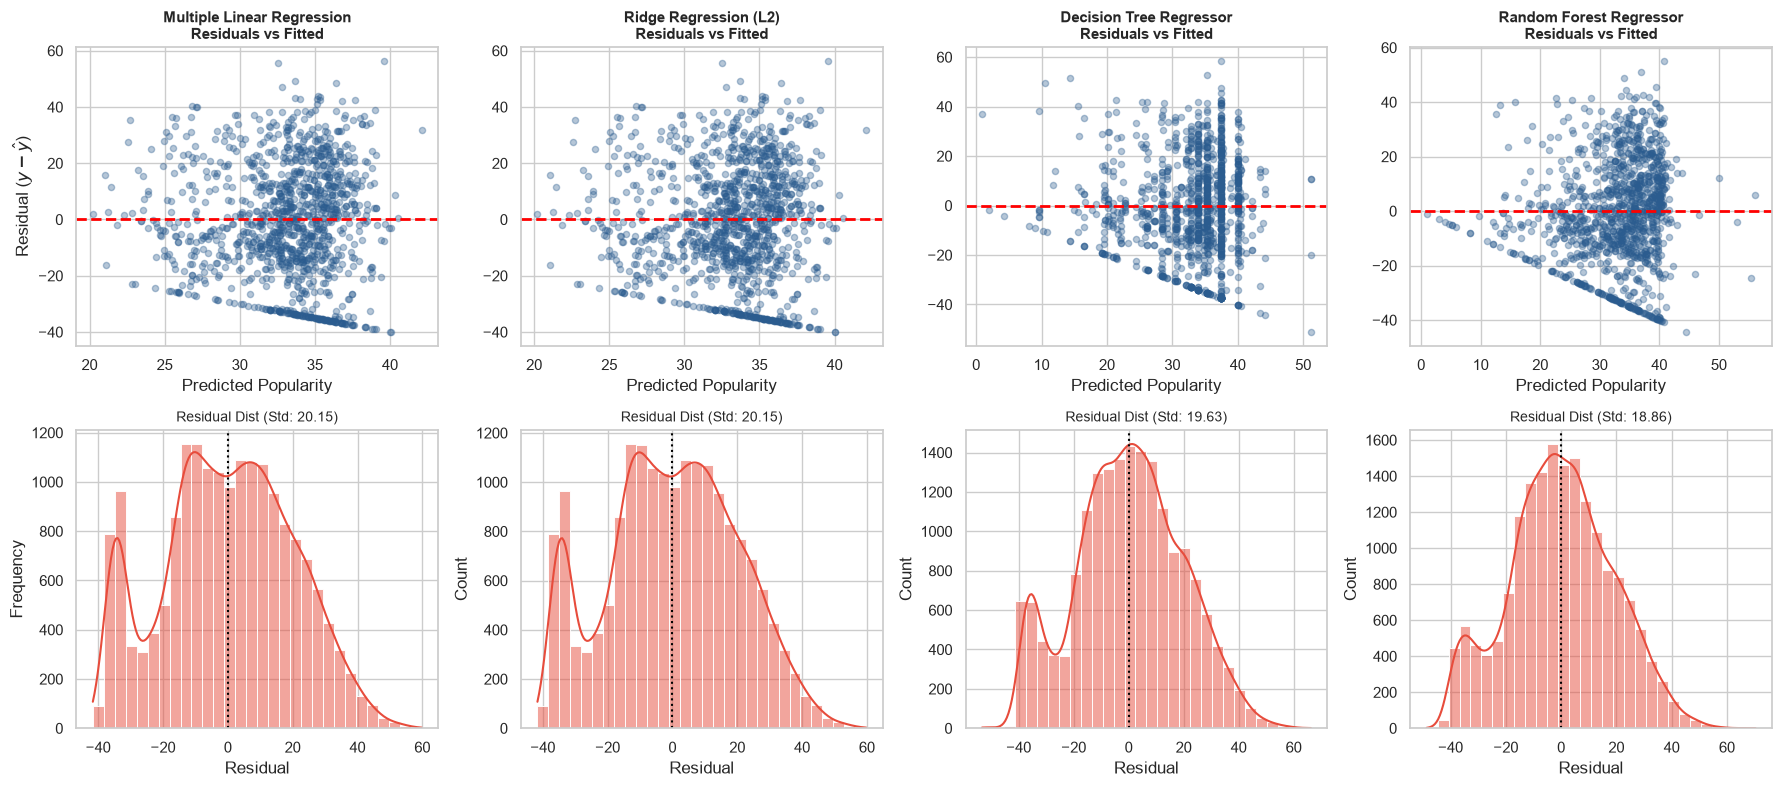

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
selected_models = ['Multiple Linear Regression', 'Ridge Regression (L2)', 'Decision Tree Regressor', 'Random Forest Regressor']

sample_idx = np.random.RandomState(42).choice(len(y_test), size=1200, replace=False)

for i, m_name in enumerate(selected_models):
    y_pred = predictions[m_name]
    res = np.array(y_test) - np.array(y_pred)
    
    # Residual vs Fitted
    axes[0, i].scatter(np.array(y_pred)[sample_idx], res[sample_idx], alpha=0.35, color='#2b5c8f', s=20)
    axes[0, i].axhline(0, color='red', linestyle='--', lw=2)
    axes[0, i].set_title(f"{m_name}\nResiduals vs Fitted", fontsize=11, weight='bold')
    axes[0, i].set_xlabel("Predicted Popularity")
    if i == 0:
        axes[0, i].set_ylabel("Residual ($y - \hat{y}$)")
        
    # Residual Distribution
    sns.histplot(res, kde=True, ax=axes[1, i], color='#e74c3c', bins=30)
    axes[1, i].axvline(0, color='black', linestyle=':', lw=1.5)
    axes[1, i].set_title(f"Residual Dist (Std: {np.std(res):.2f})", fontsize=10)
    axes[1, i].set_xlabel("Residual")
    if i == 0:
        axes[1, i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### **10. Actual vs. Predicted Visualizations**
Scatter plots of actual vs predicted popularity scores against the ideal diagonal line ($y = x$).


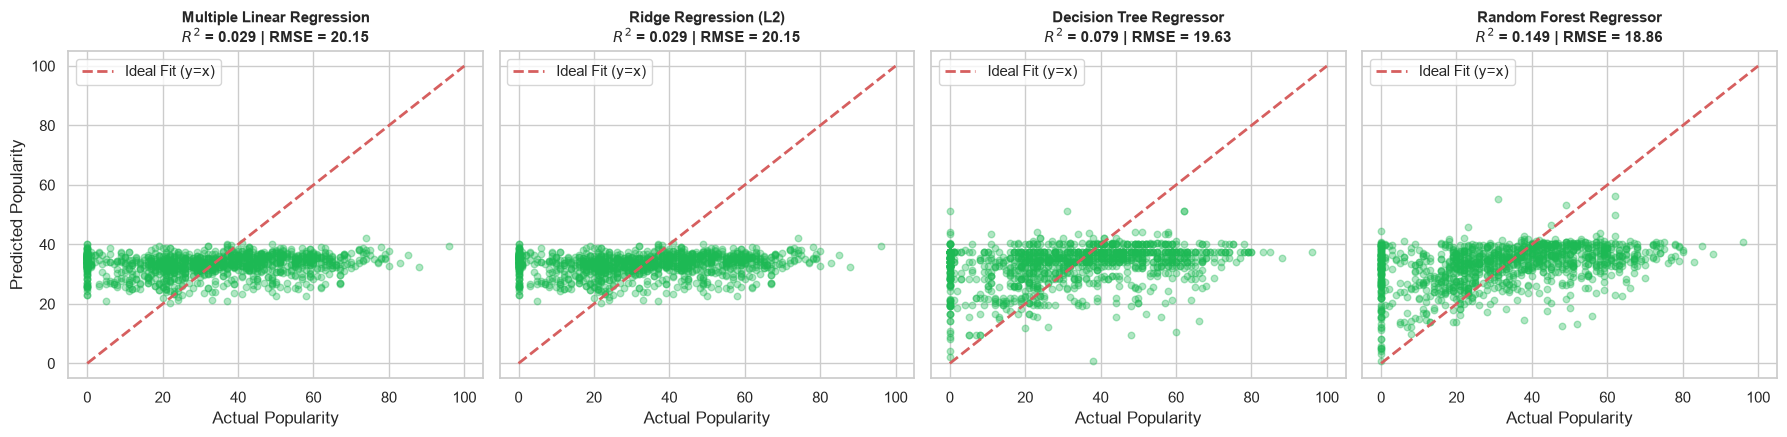

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)

for ax, m_name in zip(axes, selected_models):
    y_pred = predictions[m_name]
    r2 = r2_score(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    
    ax.scatter(np.array(y_test)[sample_idx], np.array(y_pred)[sample_idx], alpha=0.35, color='#1DB954', s=22)
    ax.plot([0, 100], [0, 100], 'r--', lw=2, label='Ideal Fit (y=x)')
    ax.set_title(f"{m_name}\n$R^2$ = {r2:.3f} | RMSE = {rmse:.2f}", fontsize=11, weight='bold')
    ax.set_xlabel("Actual Popularity")
    ax.set_xlim(-5, 105)
    ax.set_ylim(-5, 105)
    ax.legend(loc='upper left')

axes[0].set_ylabel("Predicted Popularity")
plt.tight_layout()
plt.show()

### **11. Enhanced Modeling: Integrating Genre Context & Explicit Content**
A key domain insight is that pure acoustic properties alone cannot fully capture cultural music popularity. When we incorporate `track_genre` (target-encoded strictly on training data) and the `explicit` flag:


In [13]:
from src.preprocess import prepare_enhanced_features

X_tr_enh, X_te_enh, y_tr_enh, y_te_enh, _, enh_cols = prepare_enhanced_features(df, test_size=0.2, random_state=42)

rf_enh = RandomForestRegressor(n_estimators=35, max_depth=12, min_samples_leaf=10, random_state=42)
enh_metrics, y_te_enh_pred = evaluate_model(rf_enh, X_tr_enh, y_tr_enh, X_te_enh, y_te_enh, name="Random Forest (Enhanced: Audio + Genre + Explicit)")

results.append(enh_metrics)
pd.DataFrame(results)

,Model,Train R2,Test R2,Train RMSE,Test RMSE,Train MAE,Test MAE
0,Multiple Linear Regression,0.031969,0.029321,20.280533,20.148756,16.704373,16.597664
1,Ridge Regression (L2),0.031969,0.029322,20.280533,20.148748,16.704446,16.597730
2,Lasso Regression (L1),0.031828,0.029375,20.282010,20.148195,16.721747,16.612527
3,Decision Tree Regressor,0.105581,0.078532,19.494188,19.631368,15.712880,15.826197
4,Random Forest Regressor,0.242916,0.149332,17.935221,18.862119,14.276768,15.127042
5,Random Forest (Enhanced: Audio + Genre + Expli...,0.493347,0.402504,14.672031,15.808042,10.315693,11.075972


### **12. Interpretation of Results & Key Learnings**
1. **Audio Feature Limits:**
   - Raw acoustic features (danceability, energy, tempo, acousticness) alone achieve $R^2 pprox 0.03 - 0.15$ with RMSE $pprox 18.8 - 20.1$.
   - Songs with nearly identical tempo and energy range from viral hits to underground indie releases; music popularity is heavily driven by marketing, social media trends, playlist placement, and artist recognition.
2. **Linear vs. Non-linear Models:**
   - Decision Tree and Random Forest outperform Linear Regression and Ridge/Lasso by capturing non-linear threshold effects (e.g., loudness and instrumentalness sweet spots).
3. **Contextual Gain:**
   - Adding genre context and explicit flags jumps $R^2$ to $\sim 0.40$ and drops RMSE to $\sim 15.8$, confirming that musical style is a significant contextual determinant of listening volume on Spotify.
